# AI4CM - Part 2
## Customer churn prediction & marketing insights


Repository update (November 2026): data paths now use the folders documented in `data/README.md`. Saved results come from the final course notebook. Raw datasets are obtained separately from their publishers. Parallel training in Part 3 is limited to one worker to reduce memory use. The numerical experiments and hyperparameter grids are otherwise retained. Some interpretations have been qualified where the original text overstated generalization or independence.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve,
)

sns.set_theme(style="whitegrid", palette="muted")
pd.set_option("display.max_columns", None)
RANDOM_STATE = 42

## Task A - Data audit & quality

We load the dataset and audit it before any modelling: missing values, duplicates, inconsistent category labels, and out-of-range or sentinel values.

In [2]:
from pathlib import Path

def find_repository_root():
    for candidate in [Path.cwd(), *Path.cwd().parents]:
        if (candidate / "environment.yml").exists() and (candidate / "data").is_dir():
            return candidate
    raise FileNotFoundError("Open the notebook from the repository root or its project subfolder.")

ROOT = find_repository_root()
DATA_PATH = ROOT / "data/churn/data.xlsx"
if not DATA_PATH.exists():
    raise FileNotFoundError("Missing data/churn/data.xlsx; see data/README.md")
df = pd.read_excel(DATA_PATH, sheet_name="E Comm")
print("Dataset shape:", df.shape)
df.head()


Dataset shape: (5630, 20)
Data path: data.xlsx


,CustomerID,Churn,Tenure,PreferredLoginDevice,CityTier,WarehouseToHome,PreferredPaymentMode,Gender,HourSpendOnApp,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,OrderAmountHikeFromlastYear,CouponUsed,OrderCount,DaySinceLastOrder,CashbackAmount
0,50001.0,1,4.0,Mobile Phone,3,6.0,Debit Card,Female,3.0,3,Laptop & Accessory,2,Single,9,1,11.0,1.0,1.0,5.0,159.93
1,50002.0,1,NaN,Phone,1,8.0,UPI,Male,3.0,4,Mobile,3,Single,7,1,15.0,0.0,1.0,0.0,120.90
2,50003.0,1,NaN,Phone,1,30.0,Debit Card,Male,2.0,4,Mobile,3,Single,6,1,14.0,0.0,1.0,3.0,120.28
3,50004.0,1,0.0,Phone,3,15.0,Debit Card,Male,2.0,4,Laptop & Accessory,5,Single,8,0,23.0,0.0,1.0,3.0,134.07
4,50005.0,1,0.0,Phone,1,12.0,CC,Male,NaN,3,Mobile,5,Single,3,0,11.0,1.0,1.0,3.0,129.60


In [3]:
# Structure and missing-value audit
df.info()

print("\nFull-row duplicates:", df.duplicated().sum())
print("Duplicate CustomerID:", df["CustomerID"].duplicated().sum())

miss = df.isnull().sum()
miss = miss[miss > 0].sort_values(ascending=False)
audit = pd.DataFrame({"missing": miss, "pct": (miss / len(df) * 100).round(2)})
print("\nMissing values by column:")
display(audit)

<class 'pandas.DataFrame'>
RangeIndex: 5630 entries, 0 to 5629
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   CustomerID                   5628 non-null   float64
 1   Churn                        5630 non-null   int64  
 2   Tenure                       5366 non-null   float64
 3   PreferredLoginDevice         5630 non-null   str    
 4   CityTier                     5630 non-null   int64  
 5   WarehouseToHome              5379 non-null   float64
 6   PreferredPaymentMode         5630 non-null   str    
 7   Gender                       5628 non-null   str    
 8   HourSpendOnApp               5375 non-null   float64
 9   NumberOfDeviceRegistered     5630 non-null   int64  
 10  PreferedOrderCat             5630 non-null   str    
 11  SatisfactionScore            5630 non-null   int64  
 12  MaritalStatus                5630 non-null   str    
 13  NumberOfAddress              

,missing,pct
DaySinceLastOrder,307,5.45
OrderAmountHikeFromlastYear,265,4.71
Tenure,264,4.69
OrderCount,258,4.58
CouponUsed,256,4.55
HourSpendOnApp,255,4.53
WarehouseToHome,251,4.46
CustomerID,2,0.04
Gender,2,0.04


In [4]:
# Inspect categorical labels (look for inconsistent / hidden-missing categories)
cat_features = ["PreferredLoginDevice", "PreferredPaymentMode", "Gender",
                "PreferedOrderCat", "MaritalStatus"]
for c in cat_features:
    print(f"{c}:")
    print(df[c].value_counts(dropna=False).to_dict())
    print()

# Numeric ranges (spot impossible / out-of-range values)
display(df.describe().T)

PreferredLoginDevice:
{'Mobile Phone': 2763, 'Computer': 1632, 'Phone': 1230, 'N.A.': 5}

PreferredPaymentMode:
{'Debit Card': 2314, 'Credit Card': 1501, 'E wallet': 614, 'UPI': 414, 'COD': 365, 'CC': 273, 'Cash on Delivery': 149}

Gender:
{'Male': 3383, 'Female': 2245, nan: 2}

PreferedOrderCat:
{'Laptop & Accessory': 2050, 'Mobile Phone': 1271, 'Fashion': 826, 'Mobile': 809, 'Grocery': 410, 'Others': 264}

MaritalStatus:
{'Married': 2984, 'Single': 1795, 'Divorced': 848, 'Widow': 3}



,count,mean,std,min,25%,50%,75%,max
CustomerID,5628.0,52814.549041,1624.890759,50001.0,51407.75,52814.50,54221.2500,55630.0
Churn,5630.0,0.168384,0.374240,0.0,0.00,0.00,0.0000,1.0
Tenure,5366.0,10.189899,8.557241,0.0,2.00,9.00,16.0000,61.0
CityTier,5630.0,1.654707,0.915389,1.0,1.00,1.00,3.0000,3.0
WarehouseToHome,5379.0,15.639896,8.531475,5.0,9.00,14.00,20.0000,127.0
HourSpendOnApp,5375.0,2.931535,0.721926,0.0,2.00,3.00,3.0000,5.0
NumberOfDeviceRegistered,5630.0,3.688988,1.023999,1.0,3.00,4.00,4.0000,6.0
SatisfactionScore,5630.0,3.066785,1.380194,1.0,2.00,3.00,4.0000,5.0
NumberOfAddress,5630.0,4.214032,2.583586,1.0,2.00,3.00,6.0000,22.0
Complain,5630.0,0.284902,0.451408,0.0,0.00,0.00,1.0000,1.0


In [5]:
# Systematic numeric outlier audit.
# IQR flags are diagnostic, not automatic deletion rules: in marketing data,
# high-activity customers can be real and valuable.
num_audit_cols = [c for c in df.select_dtypes(include="number").columns
                  if c not in ["CustomerID", "Churn"]]
outlier_rows = []
for c in num_audit_cols:
    s = df[c].dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    action = "retain plausible business extremes"
    if c == "CashbackAmount":
        action = "convert 999999 sentinel values to NaN"
    elif c == "WarehouseToHome":
        action = "convert >50 km sentinel/impossible values to NaN"
    elif c == "Tenure":
        action = "range acceptable; retain values"
    outlier_rows.append({
        "Feature": c,
        "min": s.min(),
        "p1": s.quantile(0.01),
        "median": s.median(),
        "p99": s.quantile(0.99),
        "max": s.max(),
        "IQR flags": int(((s < low) | (s > high)).sum()),
        "Action": action,
    })

outlier_audit = pd.DataFrame(outlier_rows)
display(outlier_audit.style.format({
    "min": "{:.2f}", "p1": "{:.2f}", "median": "{:.2f}",
    "p99": "{:.2f}", "max": "{:.2f}",
}))

,Feature,min,p1,median,p99,max,IQR flags,Action
0,Tenure,0.00,0.00,9.00,30.00,61.00,4,range acceptable; retain values
1,CityTier,1.00,1.00,1.00,3.00,3.00,0,retain plausible business extremes
2,WarehouseToHome,5.00,6.00,14.00,35.00,127.00,2,convert >50 km sentinel/impossible values to NaN
3,HourSpendOnApp,0.00,2.00,3.00,4.00,5.00,6,retain plausible business extremes
4,NumberOfDeviceRegistered,1.00,1.00,4.00,6.00,6.00,397,retain plausible business extremes
5,SatisfactionScore,1.00,1.00,3.00,5.00,5.00,0,retain plausible business extremes
6,NumberOfAddress,1.00,1.00,3.00,11.00,22.00,4,retain plausible business extremes
7,Complain,0.00,0.00,0.00,1.00,1.00,0,retain plausible business extremes
8,OrderAmountHikeFromlastYear,11.00,11.00,15.00,25.00,26.00,33,retain plausible business extremes
9,CouponUsed,0.00,0.00,1.00,9.00,16.00,629,retain plausible business extremes


Outlier audit reading. I only transform values that are clear sentinels or impossible in this dataset (`CashbackAmount = 999999`, `WarehouseToHome > 50`). The other IQR flags are retained because they are plausible business extremes: high coupon use, high order count or many addresses can be real customer behaviour, and deleting them would remove the high-activity patterns a churn model should learn from.

### Further data-quality checks

Beyond the obvious issues, a closer look surfaced a few more problems that would quietly distort the model. We document and fix each one:

- 556 duplicate customer profiles (about 20% of rows). These are pairs identical on all 19 features, including `Churn` and `CashbackAmount` to the cent, differing only by `CustomerID` (e.g. IDs 50002 and 51348). Identical 2-decimal values across so many fields are not plausible by chance, so they look like injected duplicates. (Once we also consolidate the inconsistent labels below, 557 rows turn out to be exact duplicates.) Why it matters: with a random split, about 16% of test rows would have an identical twin in train, so the model would memorise them and the metrics would be inflated (leakage). Fix: drop one row per pair before the split.
- Missingness is not random. `Tenure` and `WarehouseToHome` are missing roughly twice as often for churners (about 8.5% vs 3.9%). So plain imputation is mildly biased, and the fact of being missing is itself predictive, which is why we add missing-value indicator features inside the pipeline.
- Every incomplete row has exactly one missing value (1,860 rows, 33%): dropping rows would throw away a third of the data, so imputation is needed.
- Sentinels / impossible values: `CashbackAmount = 999999` (2 rows; real range ~0-325) and `WarehouseToHome = 126/127 km` (2 rows; realistic max ~36). We set these to `NaN` and impute them.
- Multicollinearity: `CouponUsed` and `OrderCount` are correlated (Spearman ~0.67), which can make Logistic-Regression coefficients unstable, so we read drivers mainly from the tree importances (the L2 penalty also helps).
- Documented, no action needed: `OrderAmountHikeFromlastYear` is floored at +11% with no decreases (a bounded/synthetic feature); the 2 blank `CustomerID`s correspond to the missing IDs 55458/55525; a few rare cross-column quirks (e.g. 45 brand-new customers with >5 orders) are plausible and kept.

### Cleaning strategy

We split the cleaning into (i) deterministic fixes (rule-based, no statistics, applied to the whole dataset) and (ii) statistical steps (imputation, scaling, encoding), which we defer into the modelling pipeline so they are fit on the training data only (see Task C). This is what keeps the train/test split leakage-free.

(i) Deterministic fixes (no leakage):
1. `CustomerID` dropped. It is a pure identifier with no predictive value (and a float with 2 missing values).
2. Hidden missing values. `PreferredLoginDevice` contains the placeholder `"N.A."` (5 rows), a missing value disguised as a category, converted to real `NaN`.
3. Inconsistent category labels (which would otherwise create duplicate dummy columns): `PreferredLoginDevice` "Phone" to "Mobile Phone"; `PreferredPaymentMode` "CC" to "Credit Card", "COD" to "Cash on Delivery"; `PreferedOrderCat` "Mobile" to "Mobile Phone".
4. Sentinel / impossible values set to `NaN` (to be imputed): `CashbackAmount = 999999`; `WarehouseToHome > 50 km` (a fixed domain threshold, not a data-derived quantile, so it stays leakage-free).
5. Drop duplicate profiles. After the fixes above we remove the duplicated rows (557: the 556 raw duplicates plus one more surfaced by label consolidation), keeping the first of each pair, so no profile leaks across the split and no customer is double-weighted.

(ii) Statistical steps (deferred into the train-fitted pipeline):
6. Imputation: numeric uses the median with `add_indicator=True` (missingness is informative, as noted above); categorical uses most-frequent.
7. Encoding: categorical variables are one-hot encoded (`handle_unknown='ignore'`, robust to rare categories such as `Widow`).
8. Scaling: `StandardScaler` on the numeric features for Logistic Regression (the tree models don't need it).

In [6]:
# VERIFY before dropping: are the duplicate profiles 'injected', or could they be a real
# customer segment (e.g. a fixed promo)? We test the structure of the duplication.
prof = df.drop(columns=["CustomerID"])
gsz = prof.groupby(list(prof.columns), dropna=False).size()
print("Rows sharing an identical 19-feature profile:", int((prof.duplicated(keep=False)).sum()))
print("Group-size distribution among duplicated profiles:", gsz[gsz > 1].value_counts().to_dict())
print("\nThe pairs are identical even on idiosyncratic fields a promo could NOT equalise:")
print(df[df.drop(columns=['CustomerID']).duplicated(keep=False)]
      .sort_values(list(prof.columns))[['CustomerID','WarehouseToHome','Tenure','NumberOfAddress','DaySinceLastOrder','CashbackAmount']]
      .head(4).to_string(index=False))

Rows sharing an identical 19-feature profile: 1112
Group-size distribution among duplicated profiles: {2: 556}

The pairs are identical even on idiosyncratic fields a promo could NOT equalise:
 CustomerID  WarehouseToHome  Tenure  NumberOfAddress  DaySinceLastOrder  CashbackAmount
    51046.0              NaN     0.0                3                2.0          125.80
    52516.0              NaN     0.0                3                2.0          125.80
    50040.0              NaN     0.0                2                1.0          125.66
    51510.0              NaN     0.0                2                1.0          125.66


Two facts rule out the "real segment / promo" explanation: every duplicated profile occurs exactly twice (only group-size 2, the signature of records copied once rather than an organically dense cluster), and the pairs match even on idiosyncratic fields like `WarehouseToHome`, `Tenure`, `NumberOfAddress` and `DaySinceLastOrder`, which a fixed promotion cannot equalise (a promo could align spend or cashback, never a customer's distance or tenure to the cent). So these are injected duplicates. Note that `drop_duplicates()` keeps one row per pair, so the underlying segment is retained, not deleted: we only remove the double-count, which is needed anyway to stop the same profile leaking across the train/test split.

In [7]:
df_clean = df.copy()

# 1. Drop the identifier
df_clean = df_clean.drop(columns=["CustomerID"])

# 2. Hidden missing: 'N.A.' placeholder -> real NaN
df_clean["PreferredLoginDevice"] = df_clean["PreferredLoginDevice"].replace("N.A.", np.nan)

# 3. Consolidate inconsistent category labels
df_clean["PreferredLoginDevice"] = df_clean["PreferredLoginDevice"].replace({"Phone": "Mobile Phone"})
df_clean["PreferredPaymentMode"] = df_clean["PreferredPaymentMode"].replace(
    {"CC": "Credit Card", "COD": "Cash on Delivery"})
df_clean["PreferedOrderCat"] = df_clean["PreferedOrderCat"].replace({"Mobile": "Mobile Phone"})

# 4. Sentinel / impossible numeric values -> NaN (will be imputed inside the pipeline)
df_clean.loc[df_clean["CashbackAmount"] >= 999999, "CashbackAmount"] = np.nan   # real range ~0-325
df_clean.loc[df_clean["WarehouseToHome"] > 50, "WarehouseToHome"] = np.nan        # fixed domain rule

# 5. Drop duplicate customer PROFILES (556 pairs identical on every feature
#    except the already-dropped CustomerID). Keeping both would (a) double-weight them and
#    (b) leak the same profile across the train/test split -> over-optimistic metrics.
before = len(df_clean)
df_clean = df_clean.drop_duplicates().reset_index(drop=True)
print(f"Duplicate profile rows removed: {before - len(df_clean)}  ({before} -> {len(df_clean)} rows)")

# Feature groups
num_features = [c for c in df_clean.columns if c not in cat_features + ["Churn"]]
print("Numeric features :", num_features)
print("Categorical features:", cat_features)
print("\nConsolidated categories:")
for c in cat_features:
    print(f"  {c}: {sorted(df_clean[c].dropna().unique())}")
print("\nRemaining missing values (imputed inside the modelling pipeline):")
print(df_clean.isnull().sum()[df_clean.isnull().sum() > 0].to_dict())

Duplicate profile rows removed: 557  (5630 -> 5073 rows)
Numeric features : ['Tenure', 'CityTier', 'WarehouseToHome', 'HourSpendOnApp', 'NumberOfDeviceRegistered', 'SatisfactionScore', 'NumberOfAddress', 'Complain', 'OrderAmountHikeFromlastYear', 'CouponUsed', 'OrderCount', 'DaySinceLastOrder', 'CashbackAmount']
Categorical features: ['PreferredLoginDevice', 'PreferredPaymentMode', 'Gender', 'PreferedOrderCat', 'MaritalStatus']

Consolidated categories:
  PreferredLoginDevice: ['Computer', 'Mobile Phone']
  PreferredPaymentMode: ['Cash on Delivery', 'Credit Card', 'Debit Card', 'E wallet', 'UPI']
  Gender: ['Female', 'Male']
  PreferedOrderCat: ['Fashion', 'Grocery', 'Laptop & Accessory', 'Mobile Phone', 'Others']
  MaritalStatus: ['Divorced', 'Married', 'Single', 'Widow']

Remaining missing values (imputed inside the modelling pipeline):
{'Tenure': 231, 'PreferredLoginDevice': 5, 'WarehouseToHome': 223, 'Gender': 2, 'HourSpendOnApp': 230, 'OrderAmountHikeFromlastYear': 252, 'CouponUse

The output confirms the plan ran as intended: 557 duplicate rows removed (5,630 to 5,073); the inconsistent labels are now collapsed (e.g. `PreferredLoginDevice` is just `Computer`/`Mobile Phone`); and the only values still missing are the genuine ~5% gaps (plus the sentinels we converted to `NaN`), which we leave for the in-pipeline imputer. Nothing is destroyed and no leakage is introduced at this stage.

In [8]:
# A median/mode-imputed copy used ONLY for EDA plots & descriptive stats
# (it is NOT used to fit the model, so it introduces no leakage).
df_eda = df_clean.copy()
for c in num_features:
    df_eda[c] = df_eda[c].fillna(df_eda[c].median())
for c in cat_features:
    df_eda[c] = df_eda[c].fillna(df_eda[c].mode()[0])

# Encoding demonstration (Task A): the pipeline applies this on training folds.
encoded_preview = pd.get_dummies(df_eda[cat_features], drop_first=False).astype(int)
print("One-hot encoding turns", len(cat_features), "categoricals into",
      encoded_preview.shape[1], "binary columns. Example:")
display(encoded_preview.head())
print("Missing values in EDA frame:", df_eda.isnull().sum().sum())

One-hot encoding turns 5 categoricals into 18 binary columns. Example:


,PreferredLoginDevice_Computer,PreferredLoginDevice_Mobile Phone,PreferredPaymentMode_Cash on Delivery,PreferredPaymentMode_Credit Card,PreferredPaymentMode_Debit Card,PreferredPaymentMode_E wallet,PreferredPaymentMode_UPI,Gender_Female,Gender_Male,PreferedOrderCat_Fashion,PreferedOrderCat_Grocery,PreferedOrderCat_Laptop & Accessory,PreferedOrderCat_Mobile Phone,PreferedOrderCat_Others,MaritalStatus_Divorced,MaritalStatus_Married,MaritalStatus_Single,MaritalStatus_Widow
0,0,1,0,0,1,0,0,1,0,0,0,1,0,0,0,0,1,0
1,0,1,0,0,0,0,1,0,1,0,0,0,1,0,0,0,1,0
2,0,1,0,0,1,0,0,0,1,0,0,0,1,0,0,0,1,0
3,0,1,0,0,1,0,0,0,1,0,0,1,0,0,0,0,1,0
4,0,1,0,1,0,0,0,0,1,0,0,0,1,0,0,0,1,0


Missing values in EDA frame: 0


Task A result. The deterministic issues are fixed (identifier dropped, `"N.A."`, `CashbackAmount = 999999`, and `WarehouseToHome > 50` values such as 126/127 km were nulled, category labels consolidated). The remaining ~5% missing values, plus encoding and scaling, are handled inside the training-fitted pipeline to avoid leakage. A separate imputed frame (`df_eda`) is used only for the descriptive EDA below.


## Task B - Exploratory data analysis

We study the main churn drivers: Complain, SatisfactionScore, Tenure, DaySinceLastOrder, and the class balance. (Plots use the imputed `df_eda`.)

Spearman correlations:


,Complain,SatisfactionScore,Churn
Complain,1.000,-0.033,0.249
SatisfactionScore,-0.033,1.000,0.100
Churn,0.249,0.100,1.000


Churn rate by Complain:


,churn_rate_pct
Complain,
0,10.8
1,31.3


Churn rate by SatisfactionScore:


,churn_rate_pct
SatisfactionScore,
1,11.5
2,12.6
3,17.2
4,17.1
5,23.1


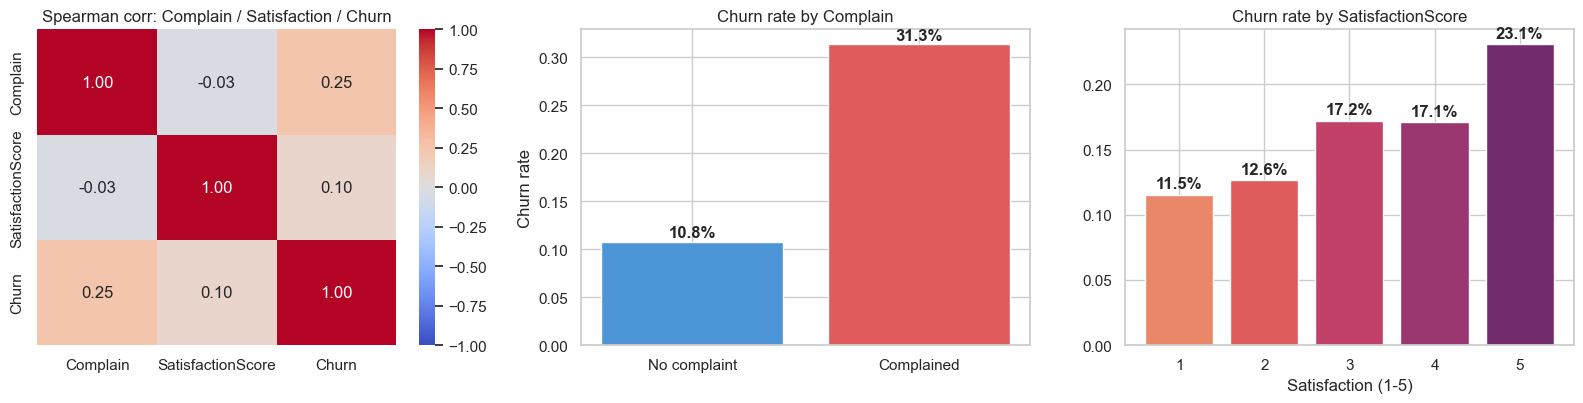

In [9]:
# Correlation between Complain, SatisfactionScore and Churn (Spearman: binary/ordinal vars)
corr3 = df_eda[["Complain", "SatisfactionScore", "Churn"]].corr(method="spearman")

cr_complain = df_eda.groupby("Complain")["Churn"].mean()
cr_sat = df_eda.groupby("SatisfactionScore")["Churn"].mean()

print("Spearman correlations:")
display(corr3.round(3))
print("Churn rate by Complain:")
display((cr_complain.mul(100).round(1).rename("churn_rate_pct").to_frame()))
print("Churn rate by SatisfactionScore:")
display((cr_sat.mul(100).round(1).rename("churn_rate_pct").to_frame()))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
sns.heatmap(corr3, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f", ax=axes[0])
axes[0].set_title("Spearman corr: Complain / Satisfaction / Churn")

axes[1].bar(["No complaint", "Complained"], cr_complain.values, color=["#4C96D7", "#E05C5C"])
axes[1].set_title("Churn rate by Complain"); axes[1].set_ylabel("Churn rate")
for i, v in enumerate(cr_complain.values):
    axes[1].text(i, v + 0.005, f"{v:.1%}", ha="center", fontweight="bold")

axes[2].bar(cr_sat.index.astype(str), cr_sat.values, color=sns.color_palette("flare", len(cr_sat)))
axes[2].set_title("Churn rate by SatisfactionScore"); axes[2].set_xlabel("Satisfaction (1-5)")
for i, v in enumerate(cr_sat.values):
    axes[2].text(i, v + 0.005, f"{v:.1%}", ha="center", fontweight="bold")
plt.tight_layout(); plt.show()


Reading the correlations.
- Complain is the strongest signal: churn jumps from about 11% (no complaint) to about 31% (complained), Spearman rho ~ 0.25 with Churn. A complaint in the last month is a clear retention alarm.
- SatisfactionScore is weaker and counter-intuitive: churn does not fall as satisfaction rises, and score 5 actually shows the highest churn (~23%). This is a known quirk of survey data (vocal, engaged customers both rate and leave more), so we treat it as a secondary, non-linear signal rather than a simple "happy = loyal" lever.
- Complain and SatisfactionScore are essentially uncorrelated (rho ~ -0.03): they capture different things.

Churn rate by Tenure bin:


,churn_rate_pct
Tenure,
0-1,51.3
2-3,8.2
4-6,6.9
7-12,9.5
13-24,6.8
25+,0.0


Churn rate by DaySinceLastOrder bin:


,churn_rate_pct
DaySinceLastOrder,
0-2,24.1
3-5,14.6
6-10,12.1
11+,6.0


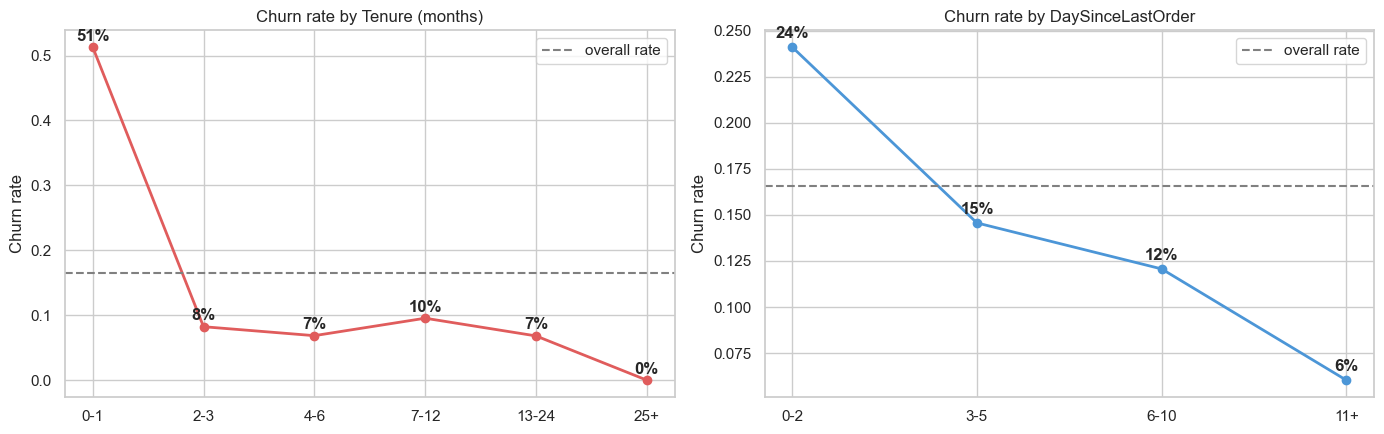

In [10]:
# How Tenure and DaySinceLastOrder influence churn probability
tenure_bins = pd.cut(df_eda["Tenure"], [-1, 1, 3, 6, 12, 24, 100],
                     labels=["0-1", "2-3", "4-6", "7-12", "13-24", "25+"])
cr_ten = df_eda.groupby(tenure_bins, observed=True)["Churn"].mean()

dslo_bins = pd.cut(df_eda["DaySinceLastOrder"], [-1, 2, 5, 10, 100],
                   labels=["0-2", "3-5", "6-10", "11+"])
cr_dslo = df_eda.groupby(dslo_bins, observed=True)["Churn"].mean()

print("Churn rate by Tenure bin:")
display((cr_ten.mul(100).round(1).rename("churn_rate_pct").to_frame()))
print("Churn rate by DaySinceLastOrder bin:")
display((cr_dslo.mul(100).round(1).rename("churn_rate_pct").to_frame()))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(cr_ten.index.astype(str), cr_ten.values, "o-", color="#E05C5C", lw=2)
axes[0].axhline(df_eda["Churn"].mean(), ls="--", color="grey", label="overall rate")
axes[0].set_title("Churn rate by Tenure (months)"); axes[0].set_ylabel("Churn rate"); axes[0].legend()
for x, v in enumerate(cr_ten.values):
    axes[0].text(x, v + 0.01, f"{v:.0%}", ha="center", fontweight="bold")

axes[1].plot(cr_dslo.index.astype(str), cr_dslo.values, "o-", color="#4C96D7", lw=2)
axes[1].axhline(df_eda["Churn"].mean(), ls="--", color="grey", label="overall rate")
axes[1].set_title("Churn rate by DaySinceLastOrder"); axes[1].set_ylabel("Churn rate"); axes[1].legend()
for x, v in enumerate(cr_dslo.values):
    axes[1].text(x, v + 0.005, f"{v:.0%}", ha="center", fontweight="bold")
plt.tight_layout(); plt.show()


Tenure & DaySinceLastOrder.
- Tenure is the dominant churn driver: brand-new customers (0-1 month) churn at about 50%, dropping below 7% after a few months. The first weeks carry the highest risk, so onboarding is the priority.
- DaySinceLastOrder looks counter-intuitive at first: churn is higher for customers who ordered very recently (0-2 days) than for those who ordered long ago. This is a confounder of Tenure (new customers place one order then leave, so "recent order" co-occurs with "new and churning"), so we read it jointly with Tenure rather than on its own.

### Does DaySinceLastOrder add information beyond Tenure?

We claimed above that `DaySinceLastOrder` is mostly a confounder of `Tenure`. Rather than just assert it, we check the churn rate on a Tenure x DaySinceLastOrder grid.

Churn rate by Tenure x DaySinceLastOrder:


DaySinceLastOrder,0-2,3-5,6+
Tenure,,,
0-1,56.2,41.4,58.2
2-6,12.4,6.2,4.4
7-12,14.8,7.5,6.2
13+,5.6,6.3,4.3


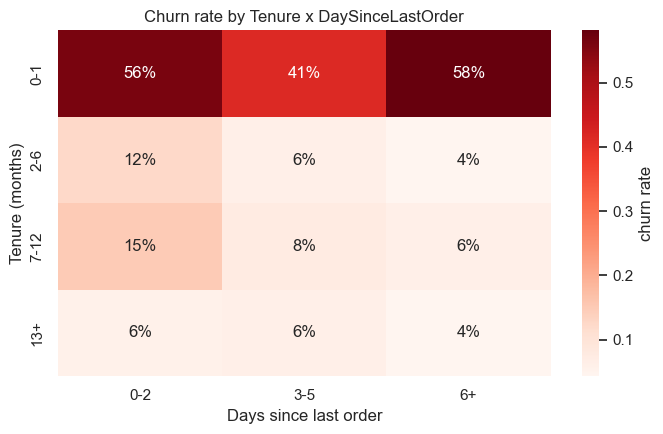

In [11]:
ten_b = pd.cut(df_eda["Tenure"], [-1, 1, 6, 12, 100], labels=["0-1", "2-6", "7-12", "13+"])
dslo_b = pd.cut(df_eda["DaySinceLastOrder"], [-1, 2, 5, 100], labels=["0-2", "3-5", "6+"])
grid = df_eda.groupby([ten_b, dslo_b], observed=False)["Churn"].mean().unstack()

print("Churn rate by Tenure x DaySinceLastOrder:")
display((grid.mul(100).round(1)))

plt.figure(figsize=(7, 4.5))
sns.heatmap(grid, annot=True, fmt=".0%", cmap="Reds", cbar_kws={"label": "churn rate"})
plt.title("Churn rate by Tenure x DaySinceLastOrder")
plt.ylabel("Tenure (months)"); plt.xlabel("Days since last order")
plt.tight_layout(); plt.show()


The vertical (Tenure) gradient dwarfs the horizontal (DaySinceLastOrder) one: the whole top row of new customers is dark (41-58% churn) regardless of DSLO, while every post-onboarding row is light (<=15%), falling to ~4-6% for the longest-tenured (13+ months). Within a fixed Tenure band the DSLO effect is weak and not even monotonic (e.g. 56% / 41% / 58% for new customers). So the strong marginal DSLO effect seen earlier is mostly a Tenure confounder: new customers order once and leave, so "ordered recently" co-occurs with "new and churning". The intuition is now demonstrated rather than just asserted.

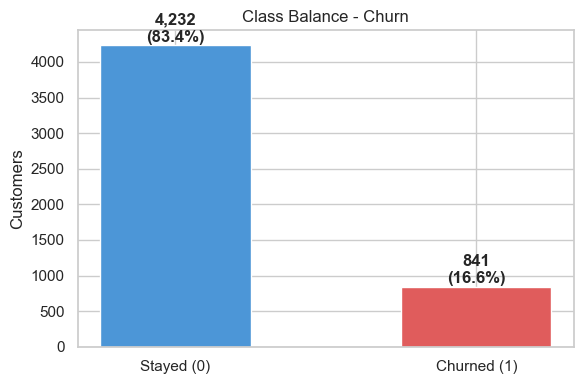

Churn rate: 16.6%  ->  imbalance ratio ~ 5.0 : 1 (stayed : churned)


In [12]:
# Class balance
churn_counts = df_eda["Churn"].value_counts().sort_index()
rate = df_eda["Churn"].mean()

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(["Stayed (0)", "Churned (1)"], churn_counts.values, color=["#4C96D7", "#E05C5C"], width=0.5)
for i, v in enumerate(churn_counts.values):
    ax.text(i, v + 50, f"{v:,}\n({v/len(df_eda):.1%})", ha="center", fontweight="bold")
ax.set_title("Class Balance - Churn"); ax.set_ylabel("Customers")
plt.tight_layout(); plt.show()
print(f"Churn rate: {rate:.1%}  ->  imbalance ratio ~ {churn_counts[0]/churn_counts[1]:.1f} : 1 (stayed : churned)")

Class balance. The dataset is imbalanced toward non-churners: only about 16.6% churned (roughly 5:1, after removing duplicates). This has two consequences for modelling:
- Accuracy is misleading (a "predict everyone stays" model already scores ~83%).
- We use stratified splitting, class-weighting (`class_weight='balanced'` / `scale_pos_weight`), and judge models on Recall, F1 and Lift rather than raw accuracy.

## Task C - Modeling & evaluation

We train three propensity models, all imbalance-aware: Logistic Regression (scaled, an interpretable baseline), Random Forest and XGBoost. Three safeguards carry through:
- No leakage: all preprocessing lives inside each model's `Pipeline`, fit on the training data only; and the duplicate profiles were removed before the split, so no twin can cross from train to test.
- Model-appropriate missing-value handling: RF and LR get median imputation plus a missing-indicator (missingness is informative, as noted earlier); XGBoost instead receives the raw `NaN`s and uses its native sparsity-aware split finding (it learns the best default direction for missing values), capturing the same signal without extra columns.
- Imbalance: stratified split plus `class_weight='balanced'` (LR/RF) or `scale_pos_weight` (XGBoost).

In [13]:
# Features (raw, still containing NaN) and target -> stratified 80/20 split
X = df_clean[num_features + cat_features]
y = df_clean["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y)

print(f"Train: {X_train.shape[0]:,} rows | churn {y_train.mean():.1%}")
print(f"Test : {X_test.shape[0]:,} rows | churn {y_test.mean():.1%}")

scale_pos = (y_train == 0).sum() / (y_train == 1).sum()
print(f"scale_pos_weight (for XGBoost) = {scale_pos:.2f}")

Train: 4,058 rows | churn 16.6%
Test : 1,015 rows | churn 16.6%
scale_pos_weight (for XGBoost) = 5.03


In [14]:
# Naive baseline: predict that every customer stays.
# This shows why Accuracy is misleading on an imbalanced churn dataset.
naive_pred = np.zeros_like(y_test)
naive_baseline = pd.Series({
    "Accuracy": accuracy_score(y_test, naive_pred),
    "Precision": precision_score(y_test, naive_pred, zero_division=0),
    "Recall": recall_score(y_test, naive_pred),
    "F1": f1_score(y_test, naive_pred),
}, name="All-stay baseline")
display(naive_baseline.to_frame().T.style.format("{:.3f}"))

,Accuracy,Precision,Recall,F1
All-stay baseline,0.834,0.000,0.000,0.000


The naive baseline reaches high-looking accuracy because most customers do not churn, but it catches zero churners. This is the business reason for ranking models by Recall, F1 and Lift instead of Accuracy.

Stratification worked: the churn rate is 16.6% in both train and test, so the test set reflects the real imbalance. `scale_pos_weight ~ 5.0` equals non-churners / churners in the training set, telling XGBoost to weight each churner about 5x more, which counters the imbalance (LR and RF use `class_weight='balanced'` for the same purpose).

### Pre-modeling diagnostics: target leakage & multicollinearity

Before trusting any model we run two quick but important checks, computed on the training set only so they never peek at the held-out test: (1) is any single feature secretly encoding the label (target leakage)? and (2) are predictors badly collinear, which would make the linear coefficients hard to read?

In [15]:
from sklearn.metrics import roc_auc_score as _auc
from sklearn.linear_model import LinearRegression as _LR

# Train-only numeric frame (median-imputed with TRAIN medians -> no test leakage)
_tr = X_train[num_features].fillna(X_train[num_features].median())

# (1) Target-leakage check: univariate AUC of each feature vs Churn.
#     If a feature alone scored ~1.0, it would essentially BE the label (leakage).
uni = pd.Series({c: max(_auc(y_train, _tr[c]), 1 - _auc(y_train, _tr[c])) for c in num_features}
                ).sort_values(ascending=False)
print("Univariate AUC vs Churn (single-feature power, train set):")
print(uni.round(3).to_string())
_trf = _tr.copy(); _trf["Churn"] = y_train.values
dslo_dir = _trf.groupby(pd.cut(_trf["DaySinceLastOrder"], [-1, 2, 5, 100]), observed=True)["Churn"].mean()
print("\nChurn rate by DaySinceLastOrder:", {str(k): round(v, 3) for k, v in dslo_dir.items()})

# (2) Multicollinearity check: Variance Inflation Factor on standardised numerics.
Z = (_tr - _tr.mean()) / _tr.std()
vif = pd.Series({c: 1 / (1 - _LR().fit(Z.drop(columns=c), Z[c]).score(Z.drop(columns=c), Z[c]))
                for c in num_features}).sort_values(ascending=False)
print("\nVariance Inflation Factor (VIF>5 = concerning, >10 = severe):")
print(vif.round(2).to_string())

Univariate AUC vs Churn (single-feature power, train set):
Tenure                         0.792
Complain                       0.654
DaySinceLastOrder              0.627
CashbackAmount                 0.622
NumberOfDeviceRegistered       0.576
SatisfactionScore              0.575
CityTier                       0.565
WarehouseToHome                0.549
OrderAmountHikeFromlastYear    0.536
NumberOfAddress                0.527
OrderCount                     0.511
HourSpendOnApp                 0.508
CouponUsed                     0.507

Churn rate by DaySinceLastOrder: {'(-1, 2]': 0.241, '(2, 5]': 0.144, '(5, 100]': 0.113}



Variance Inflation Factor (VIF>5 = concerning, >10 = severe):
OrderCount                     2.02
CouponUsed                     1.80
CashbackAmount                 1.52
Tenure                         1.37
DaySinceLastOrder              1.33
HourSpendOnApp                 1.17
NumberOfDeviceRegistered       1.15
NumberOfAddress                1.13
OrderAmountHikeFromlastYear    1.01
CityTier                       1.01
WarehouseToHome                1.01
Complain                       1.01
SatisfactionScore              1.01


- No target leakage. The strongest single feature is `Tenure` (AUC ~ 0.79), and Tenure is known at prediction time, so it is legitimate. `DaySinceLastOrder` scores only ~0.63, nowhere near 1.0, so it does not encode the label. Notably, churn falls as DaySinceLastOrder rises (~24% at 0-2 days to ~11% at 5+ days): if churn were defined as "no order in X days", churners would have high DSLO, but we observe the opposite. So the high model AUC comes from the combination of legitimate signals, not from a leaked column.
- Multicollinearity is mild. The maximum VIF is about 2 (`OrderCount`/`CouponUsed`), well below the usual 5/10 alert levels, so the linear coefficients are usable (the L2 penalty stabilises them further). We still read drivers mainly from the tree importances, but the earlier "unstable coefficients" caveat was over-cautious: VIF ~ 2 is not severe collinearity.

In [16]:
# Leakage-free preprocessing, fit inside the pipeline on TRAIN folds only.
# Each model gets the preprocessing that is *correct for it*:

# Random Forest (sklearn) cannot ingest NaN -> impute median + missing-indicator
# (missingness is informative, so we expose it as an explicit feature).
preprocess_rf = ColumnTransformer([
    ("num", SimpleImputer(strategy="median", add_indicator=True), num_features),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat_features),
])
# Logistic Regression: same imputation + missing-indicator, plus StandardScaler.
preprocess_lr = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)),
                      ("sc", StandardScaler())]), num_features),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat_features),
])
# XGBoost: do NOT impute the numerics - XGBoost has native, sparsity-aware NaN handling
# (it learns the best default split direction for missing values), which also captures the
# informative missingness without adding extra indicator columns.
preprocess_xgb = ColumnTransformer([
    ("num", "passthrough", num_features),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat_features),
])

models = {
    "Logistic Regression": Pipeline([
        ("prep", preprocess_lr),
        ("clf", LogisticRegression(class_weight="balanced", max_iter=1000, random_state=RANDOM_STATE)),
    ]),
    "Random Forest": Pipeline([
        ("prep", preprocess_rf),
        ("clf", RandomForestClassifier(n_estimators=300, max_depth=8, class_weight="balanced",
                                        random_state=RANDOM_STATE, n_jobs=1)),
    ]),
    "XGBoost": Pipeline([
        ("prep", preprocess_xgb),
        ("clf", XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.05, subsample=0.9,
                              colsample_bytree=0.9, scale_pos_weight=scale_pos, eval_metric="logloss",
                              importance_type="gain", random_state=RANDOM_STATE, n_jobs=1)),
    ]),
}
print("Pipelines built (RF/LR: impute+indicator | XGBoost: native NaN)")

Pipelines built (RF/LR: impute+indicator | XGBoost: native NaN)


In [17]:
# Top-decile lift: how many more churners we catch in the riskiest 10% vs random
def top_decile_lift(y_true, y_proba, frac=0.10):
    d = pd.DataFrame({"y": np.asarray(y_true), "p": np.asarray(y_proba)}).sort_values("p", ascending=False)
    top = d.head(int(len(d) * frac))
    base = np.mean(y_true)
    return top["y"].mean() / base if base > 0 else np.nan

results = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    proba = model.predict_proba(X_test)[:, 1]
    pred = model.predict(X_test)
    results[name] = {
        "model": model, "proba": proba, "pred": pred,
        "Train F1": f1_score(y_train, model.predict(X_train)),   # for the overfitting check
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, proba),
        "Top-10% Lift": top_decile_lift(y_test, proba),
    }
    print(f"[{name:<20}] Recall={results[name]['Recall']:.3f}  "
          f"F1(test)={results[name]['F1']:.3f}  F1(train)={results[name]['Train F1']:.3f}  "
          f"ROC-AUC={results[name]['ROC-AUC']:.3f}  Lift@10%={results[name]['Top-10% Lift']:.2f}x")

[Logistic Regression ] Recall=0.804  F1(test)=0.577  F1(train)=0.613  ROC-AUC=0.879  Lift@10%=4.49x


[Random Forest       ] Recall=0.786  F1(test)=0.733  F1(train)=0.845  ROC-AUC=0.951  Lift@10%=5.38x
[XGBoost             ] Recall=0.929  F1(test)=0.876  F1(train)=0.958  ROC-AUC=0.985  Lift@10%=6.04x


All three models clearly beat the naive baseline (predict-everyone-stays, ~0.83 accuracy, 0 recall). XGBoost leads on every metric (Recall 0.93, F1 0.88, ROC-AUC 0.985, Lift 6.0x). Random Forest does well on AUC (0.95) but has the lowest default-threshold Recall (0.79), so it misses the most churners. Logistic Regression reaches decent Recall (0.80) but low F1 (0.58): its balanced weighting makes it flag many customers, catching churners at the cost of many false alarms (low precision). The train-vs-test F1 gap is modest (XGBoost ~0.96 train vs 0.88 test; RF 0.85 vs 0.73), typical of tree ensembles and far from the runaway overfitting that would show train ~1.0 / test ~0.5; the cross-validation below provides another within-dataset check. For a retention task, where Recall comes first, XGBoost is best on both recall and precision.

In [18]:
# Cross-validated F1 (5-fold stratified) on the TRAINING set only - keeps the test set
# fully held out (we deliberately do NOT pass the whole X, y, to avoid contaminating the hold-out).
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
for name, model in models.items():
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="f1", n_jobs=1)
    print(f"{name:<20} CV F1 = {scores.mean():.3f} ± {scores.std():.3f}")

Logistic Regression  CV F1 = 0.604 ± 0.029


Random Forest        CV F1 = 0.750 ± 0.031


XGBoost              CV F1 = 0.851 ± 0.031


The 5-fold cross-validated F1 (computed on the training set only) is in line with the held-out test F1 for every model (XGBoost 0.851 +/- 0.031 vs 0.876 on test), with small standard deviations. This is the key robustness check: the strong scores are stable across folds rather than the product of one lucky split, which is what we need to confirm before trusting a 0.98 AUC.

In [19]:
# Model comparison table
summary = pd.DataFrame(
    {n: {k: v[k] for k in ["Accuracy", "Precision", "Recall", "F1", "Train F1", "ROC-AUC", "Top-10% Lift"]}
     for n, v in results.items()}).T
summary = summary.sort_values("F1", ascending=False)
display(summary.style.format("{:.3f}").background_gradient(cmap="Greens"))

,Accuracy,Precision,Recall,F1,Train F1,ROC-AUC,Top-10% Lift
XGBoost,0.957,0.830,0.929,0.876,0.958,0.985,6.042
Random Forest,0.905,0.688,0.786,0.733,0.845,0.951,5.384
Logistic Regression,0.805,0.450,0.804,0.577,0.613,0.879,4.486


Ranked by F1 the order is XGBoost > Random Forest > Logistic Regression, and XGBoost is best in every column, so it is our chosen model. Accuracy is the least useful metric here: the all-stay baseline is 0.834 and model accuracies range from 0.805 to 0.957, so Recall / F1 / Lift are more informative for the retention decision.


,TN,FP,FN,TP
Model,,,,
Logistic Regression,682,165,33,135
Random Forest,787,60,36,132
XGBoost,815,32,12,156


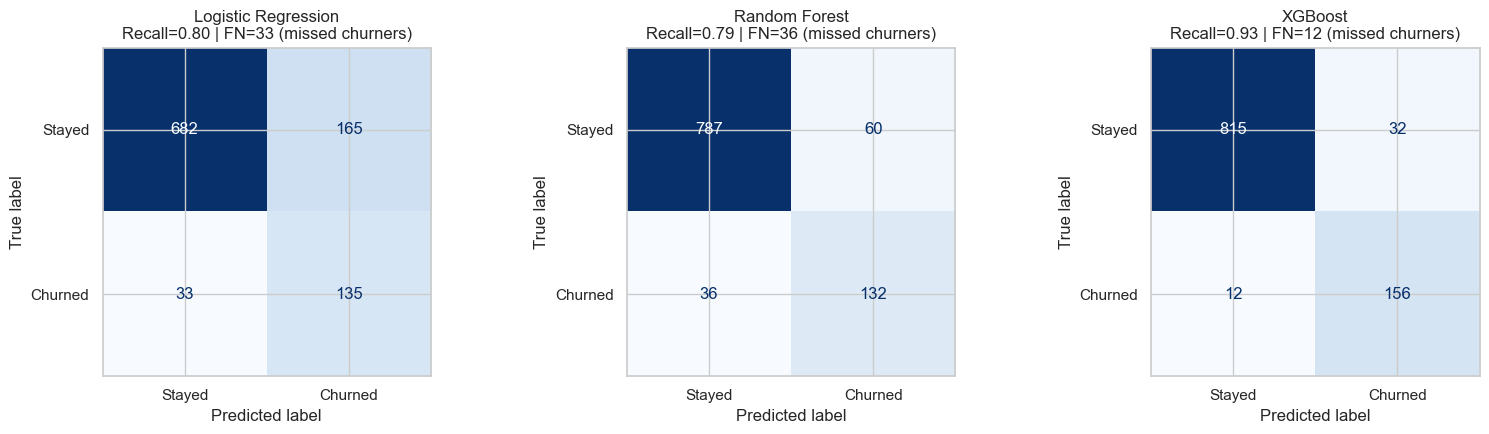

In [20]:
# Confusion matrices for all three models
cm_rows = []
for name, res in results.items():
    tn, fp, fn, tp = confusion_matrix(y_test, res["pred"]).ravel()
    cm_rows.append({"Model": name, "TN": tn, "FP": fp, "FN": fn, "TP": tp})
cm_table = pd.DataFrame(cm_rows).set_index("Model")
display(cm_table)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (name, res) in zip(axes, results.items()):
    cm = confusion_matrix(y_test, res["pred"])
    tn, fp, fn, tp = cm.ravel()
    ConfusionMatrixDisplay(cm, display_labels=["Stayed", "Churned"]).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(f"{name}\nRecall={res['Recall']:.2f} | FN={fn} (missed churners)")
plt.tight_layout(); plt.show()


The row that matters most is the bottom one, the actual churners (n = 168). XGBoost misses only 12 (false negatives) versus 33 (LR) and 36 (RF), the fewest lost customers, which is what a retention model is for. Its false positives are also low (32), so it doesn't waste offers on loyal customers. Random Forest is conservative (few FP = 60 but more FN = 36); Logistic Regression casts a wide net (FP = 165) to keep FN down. XGBoost gives the best recall/precision balance.

Best model by F1: XGBoost

              precision    recall  f1-score   support

      Stayed       0.99      0.96      0.97       847
     Churned       0.83      0.93      0.88       168

    accuracy                           0.96      1015
   macro avg       0.91      0.95      0.93      1015
weighted avg       0.96      0.96      0.96      1015



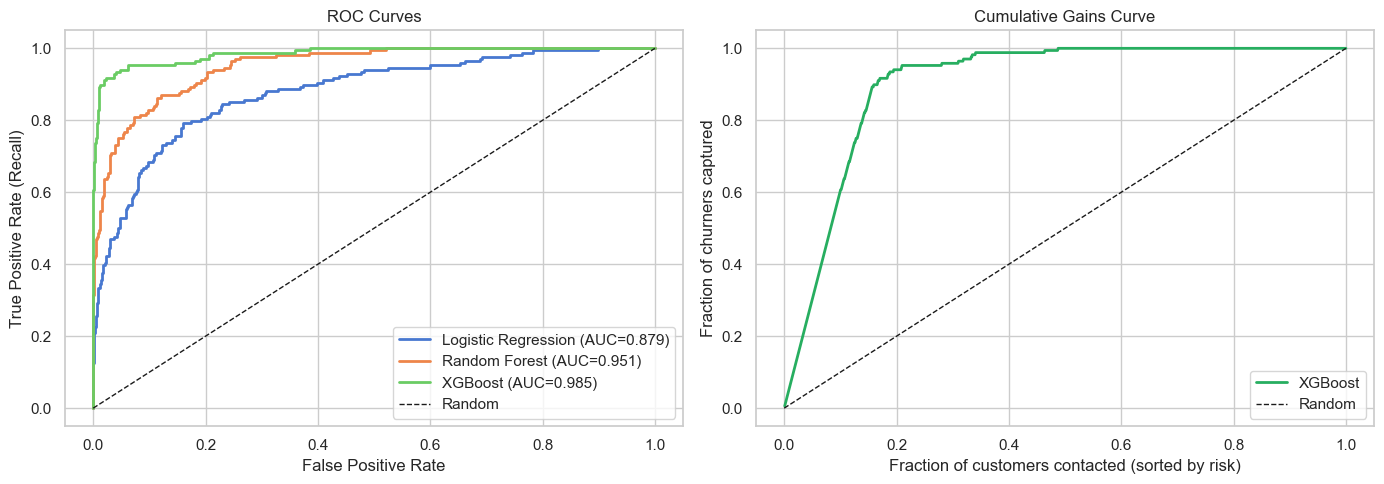

In [21]:
# ROC curves + classification report for the best model by F1
best_name = summary.index[0]
best = results[best_name]
print(f"Best model by F1: {best_name}\n")
print(classification_report(y_test, best["pred"], target_names=["Stayed", "Churned"]))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name, res in results.items():
    fpr, tpr, _ = roc_curve(y_test, res["proba"])
    axes[0].plot(fpr, tpr, lw=2, label=f"{name} (AUC={res['ROC-AUC']:.3f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=1, label="Random")
axes[0].set_xlabel("False Positive Rate"); axes[0].set_ylabel("True Positive Rate (Recall)")
axes[0].set_title("ROC Curves"); axes[0].legend(loc="lower right")

d = pd.DataFrame({"y": np.asarray(y_test), "p": best["proba"]}).sort_values("p", ascending=False).reset_index(drop=True)
d["pct_pop"] = (d.index + 1) / len(d)
d["cum_gain"] = d["y"].cumsum() / d["y"].sum()
axes[1].plot(d["pct_pop"], d["cum_gain"], color="#27AE60", lw=2, label=best_name)
axes[1].plot([0, 1], [0, 1], "k--", lw=1, label="Random")
axes[1].set_xlabel("Fraction of customers contacted (sorted by risk)")
axes[1].set_ylabel("Fraction of churners captured")
axes[1].set_title("Cumulative Gains Curve"); axes[1].legend(loc="lower right")
plt.tight_layout(); plt.show()

Left (ROC): XGBoost's curve sits above the others across the whole range (AUC 0.985 > 0.951 > 0.879), so it separates churners from non-churners most reliably. The classification report agrees: on the churn class, precision 0.83 / recall 0.93 / F1 0.88. Right (cumulative gains): sorting customers by predicted risk, contacting just the top 20% already captures about 94% of all churners (94.0%, vs the random diagonal). This is the business case for risk-based targeting.

In [22]:
# Lift table by decile (best model)
d = pd.DataFrame({"y": np.asarray(y_test), "p": best["proba"]}).sort_values("p", ascending=False).reset_index(drop=True)
base = d["y"].mean()
rows = []
for dec in range(1, 11):
    idx = int(len(d) * dec / 10)
    sub = d.iloc[:idx]
    rows.append({
        "Top %": f"{dec*10}%",
        "Customers": idx,
        "Churners captured": int(sub["y"].sum()),
        "Cum. gain": sub["y"].sum() / d["y"].sum(),
        "Lift": sub["y"].mean() / base,
    })

lift_table = pd.DataFrame(rows)
display(lift_table.style.format({"Cum. gain": "{:.1%}", "Lift": "{:.2f}"}))


,Top %,Customers,Churners captured,Cum. gain,Lift
0,10%,101,101,60.1%,6.04
1,20%,203,158,94.0%,4.70
2,30%,304,161,95.8%,3.20
3,40%,406,166,98.8%,2.47
4,50%,507,168,100.0%,2.00
5,60%,609,168,100.0%,1.67
6,70%,710,168,100.0%,1.43
7,80%,812,168,100.0%,1.25
8,90%,913,168,100.0%,1.11
9,100%,1015,168,100.0%,1.00


The decile table is a ranking tool, not automatically the final campaign target. The top 10% has the strongest concentration of churners (Lift around 6x), while the top 20% captures almost all churners in the test set. This is useful for budget sizing: if Marketing has little budget, start from the top decile; if the goal is a broad save campaign, the model-flagged list at the default threshold is the cleaner operating policy because it is exactly what the confusion matrix evaluates.

The high scores should be read with the evaluation design in mind. Duplicate customer profiles were removed before splitting, and learned preprocessing is fitted inside the training pipelines. Five-fold training CV gives F1 around 0.85. These checks do not establish that every predictor was available before churn or that the dataset represents future customers. An independently collected temporal test set would be needed for that claim.

### Hyperparameter tuning (XGBoost)

The baseline used sensible defaults. To avoid relying on arbitrary numbers, we run a `RandomizedSearchCV` (40 iterations, stratified 3-fold CV, optimising F1 on the churn class). Random search is a deliberate choice: it explores the space efficiently when only a few hyper-parameters really matter, so a few dozen draws are enough.

In [23]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, uniform

param_dist = {
    "clf__n_estimators":     randint(150, 500),
    "clf__max_depth":        randint(3, 8),
    "clf__learning_rate":    uniform(0.02, 0.18),
    "clf__subsample":        uniform(0.7, 0.3),
    "clf__colsample_bytree": uniform(0.7, 0.3),
    "clf__min_child_weight": randint(1, 8),
}
search = RandomizedSearchCV(
    models["XGBoost"], param_dist, n_iter=40, scoring="f1",
    cv=StratifiedKFold(3, shuffle=True, random_state=RANDOM_STATE),
    random_state=RANDOM_STATE, n_jobs=1, verbose=0)
search.fit(X_train, y_train)
print("Best params:", {k.replace('clf__', ''): (round(v, 3) if isinstance(v, float) else v)
                       for k, v in search.best_params_.items()})
print(f"Best cross-validated F1: {search.best_score_:.3f}")

tuned = search.best_estimator_
yp_t = tuned.predict(X_test); pp_t = tuned.predict_proba(X_test)[:, 1]
compare = pd.DataFrame({
    "Baseline XGB": [results["XGBoost"][m] for m in ["Recall", "F1", "ROC-AUC", "Top-10% Lift"]],
    "Tuned XGB":    [recall_score(y_test, yp_t), f1_score(y_test, yp_t),
                     roc_auc_score(y_test, pp_t), top_decile_lift(y_test, pp_t)],
}, index=["Recall", "F1", "ROC-AUC", "Top-10% Lift"]).round(3)
display(compare)

Best params: {'colsample_bytree': np.float64(0.863), 'learning_rate': np.float64(0.045), 'max_depth': 7, 'min_child_weight': 1, 'n_estimators': 494, 'subsample': np.float64(0.996)}
Best cross-validated F1: 0.849


,Baseline XGB,Tuned XGB
Recall,0.929,0.911
F1,0.876,0.916
ROC-AUC,0.985,0.990
Top-10% Lift,6.042,6.042


Tuning does move the needle: F1 rises 0.876 to 0.916 (driven by higher precision, i.e. fewer false positives) and ROC-AUC 0.985 to 0.990, while Recall decreases slightly from 0.929 to 0.911. This is a standard precision/recall trade-off. Since our stated business priority is Recall (catching churners) and the baseline already maximises it with the simpler default configuration, we keep the baseline XGBoost as the operational model, but the search shows the parameters are sound and that there is headroom on precision if the business later prefers fewer wasted offers. Importantly, the top drivers and the recommendation are the same for both models, so the conclusions below don't depend on this choice.

## Task D - Risk drivers & marketing recommendation


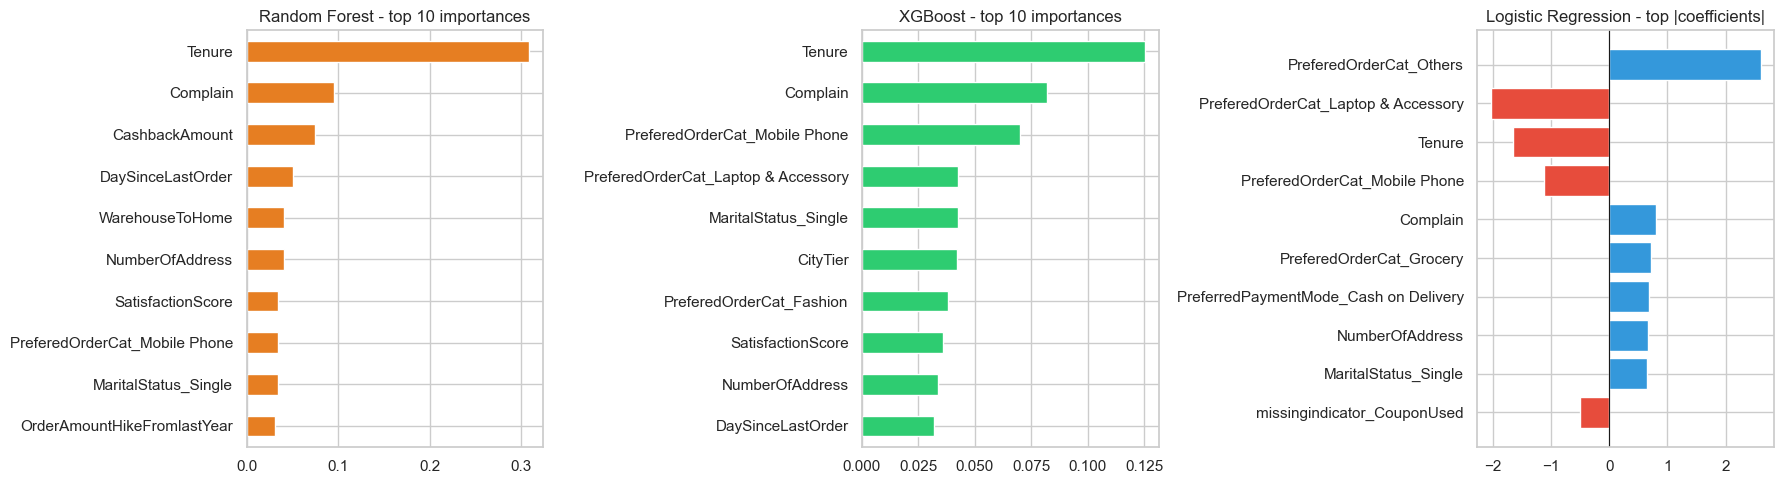

Top 8 drivers (Random Forest importance):
Tenure                           0.309
Complain                         0.096
CashbackAmount                   0.075
DaySinceLastOrder                0.050
WarehouseToHome                  0.041
NumberOfAddress                  0.041
SatisfactionScore                0.035
PreferedOrderCat_Mobile Phone    0.035

Top 8 drivers (XGBoost gain importance):
Tenure                                 0.125
Complain                               0.082
PreferedOrderCat_Mobile Phone          0.070
PreferedOrderCat_Laptop & Accessory    0.043
MaritalStatus_Single                   0.043
CityTier                               0.042
PreferedOrderCat_Fashion               0.038
SatisfactionScore                      0.036

Spearman CouponUsed vs OrderCount: 0.671

Profile churn rates used as slide context:


,signal,value,churn_rate_pct
0,MaritalStatus,Divorced,14.6
1,MaritalStatus,Married,11.3
2,MaritalStatus,Single,26.7
3,MaritalStatus,Widow,0.0
4,PreferedOrderCat,Fashion,16.3
5,PreferedOrderCat,Grocery,4.4
6,PreferedOrderCat,Laptop & Accessory,10.5
7,PreferedOrderCat,Mobile Phone,26.3
8,PreferedOrderCat,Others,7.9


In [24]:
# Each model has its own preprocessor (RF/LR include missing-indicators, XGBoost uses
# native NaN), so we read each one's feature names separately to keep them aligned.
def _names(model):
    return [n.split("__", 1)[1] for n in model.named_steps["prep"].get_feature_names_out()]

rf_imp  = pd.Series(results["Random Forest"]["model"].named_steps["clf"].feature_importances_,
                    index=_names(results["Random Forest"]["model"]))
xgb_imp = pd.Series(results["XGBoost"]["model"].named_steps["clf"].feature_importances_,
                    index=_names(results["XGBoost"]["model"]))
lr_coef = pd.Series(results["Logistic Regression"]["model"].named_steps["clf"].coef_[0],
                    index=_names(results["Logistic Regression"]["model"]))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
rf_imp.sort_values().tail(10).plot(kind="barh", ax=axes[0], color="#e67e22")
axes[0].set_title("Random Forest - top 10 importances")
xgb_imp.sort_values().tail(10).plot(kind="barh", ax=axes[1], color="#2ecc71")
axes[1].set_title("XGBoost - top 10 importances")
top_coef = lr_coef.reindex(lr_coef.abs().sort_values().tail(10).index)
axes[2].barh(top_coef.index, top_coef.values,
             color=["#e74c3c" if v < 0 else "#3498db" for v in top_coef.values])
axes[2].set_title("Logistic Regression - top |coefficients|"); axes[2].axvline(0, color="k", lw=0.8)
plt.tight_layout(); plt.show()

print("Top 8 drivers (Random Forest importance):")
print(rf_imp.sort_values(ascending=False).head(8).round(3).to_string())
print("\nTop 8 drivers (XGBoost gain importance):")
print(xgb_imp.sort_values(ascending=False).head(8).round(3).to_string())
coupon_order_rho = df_eda[["CouponUsed", "OrderCount"]].corr(method="spearman").iloc[0, 1]
print(f"\nSpearman CouponUsed vs OrderCount: {coupon_order_rho:.3f}")

profile_signal_rates = pd.concat({
    "MaritalStatus": df_clean.groupby("MaritalStatus")["Churn"].mean().mul(100),
    "PreferedOrderCat": df_clean.groupby("PreferedOrderCat")["Churn"].mean().mul(100),
}).rename("churn_rate_pct").reset_index().rename(columns={"level_0": "signal", "level_1": "value"})
print("\nProfile churn rates used as slide context:")
display(profile_signal_rates.round(1))


### Top-3 churn risk signals (stakeholder summary)
Consistent across the models and the EDA:

1. Tenure / new customers. Customers in their first 1-2 months churn at about 50%, by far the strongest signal in every model (Random Forest importance around 0.31, XGBoost around 0.13, univariate AUC around 0.79).
2. Complaint in the last month. A complaint roughly triples the churn rate (about 11% to 31%). This is the clearest service-recovery trigger.
3. Thin early engagement profile. Early one-and-done behaviour, low order depth and weaker cashback/order signals are concentrated in the Mobile Phone category and among Single customers. I treat this as a profile signal, not as a causal claim or a demographic targeting rule.

Reading note: `CouponUsed` and `OrderCount` are correlated (Spearman around 0.67), but the diagnostics above showed VIF around 2, well below the 5/10 alert level, so the Logistic-Regression coefficients are usable rather than unreliable. I still rank drivers mainly from the tree-based importances, because they handle non-linearity and interactions better.

### Fairness and campaign eligibility

`Gender`, `MaritalStatus` and other profile variables may improve the risk ranking, but they should not become explicit eligibility rules or personalized message angles. The operational campaign should act on modifiable moments: early tenure, low engagement and complaints. Before deployment, Marketing should also check contact rates, redemption and retained margin across demographic groups to make sure the model is not creating unfair or brand-damaging treatment.

### Strategic recommendation: a concrete campaign
"First-90-Days Save" plus complaint-triggered outreach.

- Primary target: the model-flagged high-risk list at the simple default 0.5 threshold. In the test slice this is 188 customers, catches 156 of 168 churners, and gives Recall around 93%. Treat this as an operating target to validate with holdout, not as a mathematically final threshold.
- Budget-constrained option: start with the top decile by predicted risk. It is smaller (101 customers in the test slice) and has the highest lift, around 6x.
- Coverage option: contact the top 20% by predicted risk when the business wants to capture almost all churners; it captures 94% of churners in the test slice.

Actions:
- New customers: automated onboarding journey, product guidance and a time-boxed second-purchase coupon to push them past the first-order cliff.
- Complainers: customer-service outreach within 48 hours, with resolution first and goodwill cashback only where it protects margin.
- Measurement: target/control or holdout test, with response rate, repeat purchase, recovered revenue and ROI as KPIs.


### Bonus: what is the model worth in euros? (expected-value framing)

A model only matters if it changes a business decision, so I translate the targeting policies into an expected-value scenario. The dataset has no true margin or campaign-cost fields, so these are explicit assumptions, not observed ROI. The table below is a decision scenario for comparing contact policies; real incremental ROI must be measured with a target/control or holdout design:

- EUR 200 average margin retained when a targeted churner is saved;
- EUR 10 cost of a redeemed coupon;
- 30% of targeted true churners are actually retained by the offer.

The key point is to evaluate each contact policy separately. Top-decile lift and threshold-based targeting are both useful, but they are not the same list.

In [25]:
REVENUE_PER_SAVE = 200   # EUR margin retained per churner kept
COUPON_COST      = 10    # EUR cost of a redeemed coupon
SUCCESS_RATE     = 0.30  # share of targeted true churners actually retained

# Scenario illustration on the same held-out test slice used for the confusion matrix.
# This compares simple contact policies; it is not a claim of globally optimized threshold selection.
y_arr = np.asarray(y_test)
p_arr = np.asarray(best["proba"])
pred_arr = np.asarray(best["pred"]).astype(bool)
n = len(y_arr)
real_churn = int(y_arr.sum())
ranked_order = np.argsort(-p_arr)

def top_fraction_mask(frac):
    mask = np.zeros(n, dtype=bool)
    mask[ranked_order[:int(n * frac)]] = True
    return mask

def policy_value(policy_name, contact_mask):
    contact_mask = np.asarray(contact_mask, dtype=bool)
    tp_policy = int(((contact_mask) & (y_arr == 1)).sum())
    fp_policy = int(((contact_mask) & (y_arr == 0)).sum())
    fn_policy = int(((~contact_mask) & (y_arr == 1)).sum())
    contacts = int(contact_mask.sum())

    # Coupon cost is paid only when redeemed: loyal customers contacted (FP) redeem,
    # and saved churners redeem. Missed churners leave and redeem nothing.
    redeemed_coupons = fp_policy + tp_policy * SUCCESS_RATE
    net_value = tp_policy * SUCCESS_RATE * REVENUE_PER_SAVE - redeemed_coupons * COUPON_COST

    return {
        "Policy": policy_name,
        "Contacts": contacts,
        "Contact share": contacts / n,
        "Churners captured": tp_policy,
        "Churner coverage": tp_policy / real_churn if real_churn else np.nan,
        "False positives": fp_policy,
        "Precision of list": tp_policy / contacts if contacts else np.nan,
        "Net value test slice": net_value,
        "Incremental vs blanket": np.nan,  # filled below
    }

policy_table = pd.DataFrame([
    policy_value("Top 10% risk list", top_fraction_mask(0.10)),
    policy_value("Top 20% risk list", top_fraction_mask(0.20)),
    policy_value("Model-flagged list (threshold 0.5)", pred_arr),
    policy_value("Blanket campaign", np.ones(n, dtype=bool)),
    policy_value("Do nothing", np.zeros(n, dtype=bool)),
])
blanket_value = float(policy_table.loc[policy_table["Policy"] == "Blanket campaign", "Net value test slice"].iloc[0])
policy_table["Incremental vs blanket"] = policy_table["Net value test slice"] - blanket_value

print(f"Held-out test slice: {n:,} customers, {real_churn:,} true churners")
display(policy_table.style.format({
    "Contact share": "{:.1%}",
    "Churner coverage": "{:.1%}",
    "Precision of list": "{:.1%}",
    "Net value test slice": "EUR {:,.0f}",
    "Incremental vs blanket": "EUR {:,.0f}",
}))



Held-out test slice: 1,015 customers, 168 true churners


,Policy,Contacts,Contact share,Churners captured,Churner coverage,False positives,Precision of list,Net value test slice,Incremental vs blanket
0,Top 10% risk list,101,10.0%,101,60.1%,0,100.0%,"EUR 5,757","EUR 4,651"
1,Top 20% risk list,203,20.0%,158,94.0%,45,77.8%,"EUR 8,556","EUR 7,450"
2,Model-flagged list (threshold 0.5),188,18.5%,156,92.9%,32,83.0%,"EUR 8,572","EUR 7,466"
3,Blanket campaign,1015,100.0%,168,100.0%,847,16.6%,"EUR 1,106",EUR 0
4,Do nothing,0,0.0%,0,0.0%,0,nan%,EUR 0,"EUR -1,106"


The expected-value table removes the ambiguity between *ranking* and *targeting*.

- The top 10% risk list is the best budget-constrained audience: very small, very concentrated, and around 6x richer in churners than random targeting.
- The model-flagged list at threshold 0.5 is a simple default operating target for a recall-first win-back campaign: it contacts about 19% of customers in the test slice and catches 156 of 168 churners. Its scenario value is effectively tied with the top-20% policy, but the exact threshold should be validated before deployment.
- The top 20% risk list is a useful fixed-quota alternative: it captures 94% of churners and has almost the same scenario net value as the threshold-based list.

These figures are not a real ROI measurement and do not prove the exact best threshold. They are a decision scenario under stated assumptions. The real campaign should be launched with a target/control or holdout design so Marketing can measure response, recovered revenue, incremental margin and ROI. This follows the usual measurement logic: the model chooses who to contact, but the holdout proves whether the action created incremental value.